# Day 11: Supervised Learning with Logistic Regression, SVM and Decision Trees

The project predicts whether a bank customer will accept a personal loan offer.

- Target variable: Personal Loan, where 0 means declined and 1 means accepted
- Problem type: supervised learning, binary classification
- Models used: Logistic Regression, Multivariate Logistic Regression, Support Vector Machine and Decision Tree

The pipeline: data collection, extraction, cleaning, EDA, feature engineering, training, evaluation and visualization.

## Loading the Bank Personal Loan Dataset

The dataset is fetched from Kaggle through kagglehub into a local cache.

In [1]:
import os

import kagglehub

path = kagglehub.dataset_download("krantiswalke/bank-personal-loan-modelling")
print("Dataset folder:", path)

for root, dirs, files in os.walk(path):
    for file_name in files:
        if file_name.endswith(".csv"):
            csv_file = os.path.join(root, file_name)
            print("CSV found at:", csv_file)

100%|██████████| 60.6k/60.6k [00:00<00:00, 19.7MB/s]

Extracting files...
Dataset folder: /root/.cache/kagglehub/datasets/krantiswalke/bank-personal-loan-modelling/versions/1
CSV found at: /root/.cache/kagglehub/datasets/krantiswalke/bank-personal-loan-modelling/versions/1/Bank_Personal_Loan_Modelling.csv


In [2]:
import pandas as pd

df = pd.read_csv(csv_file)
df.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


## Basic Data Inspection

### Shape and Columns

In [3]:
print(df.shape)
df.columns

(5000, 14)


Index(['ID', 'Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg',
       'Education', 'Mortgage', 'Personal Loan', 'Securities Account',
       'CD Account', 'Online', 'CreditCard'],
      dtype='object')

### Data Types

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


### Statistical Summary

In [5]:
df.describe()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937938,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747659,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


## Data Cleaning and Preprocessing

Raw data rarely arrives clean. It can hide missing values, duplicate rows and columns that add nothing to the prediction, all of which slow training down and skew results.

### Dropping the ID Column

The ID only numbers the rows, it carries no useful pattern.

In [6]:
df.drop(columns=["ID"], inplace=True)
df.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


### Missing Values

In [7]:
df.isnull().sum()

,0
Age,0
Experience,0
Income,0
ZIP Code,0
Family,0
CCAvg,0
Education,0
Mortgage,0
Personal Loan,0
Securities Account,0


No column reports missing entries, so nothing needs to be filled.

### Duplicates

In [8]:
print("Duplicate rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

Duplicate rows: 0


### Target Distribution

Class 0 means the customer did not accept the loan, class 1 means the customer did. The counts show a strong imbalance, which matters later when reading precision and recall.

In [9]:
df["Personal Loan"].value_counts()

,count
Personal Loan,
0,4520
1,480


## Feature Engineering

Useless or redundant features are removed and the remaining ones are checked for correlation.

### Correlation Matrix

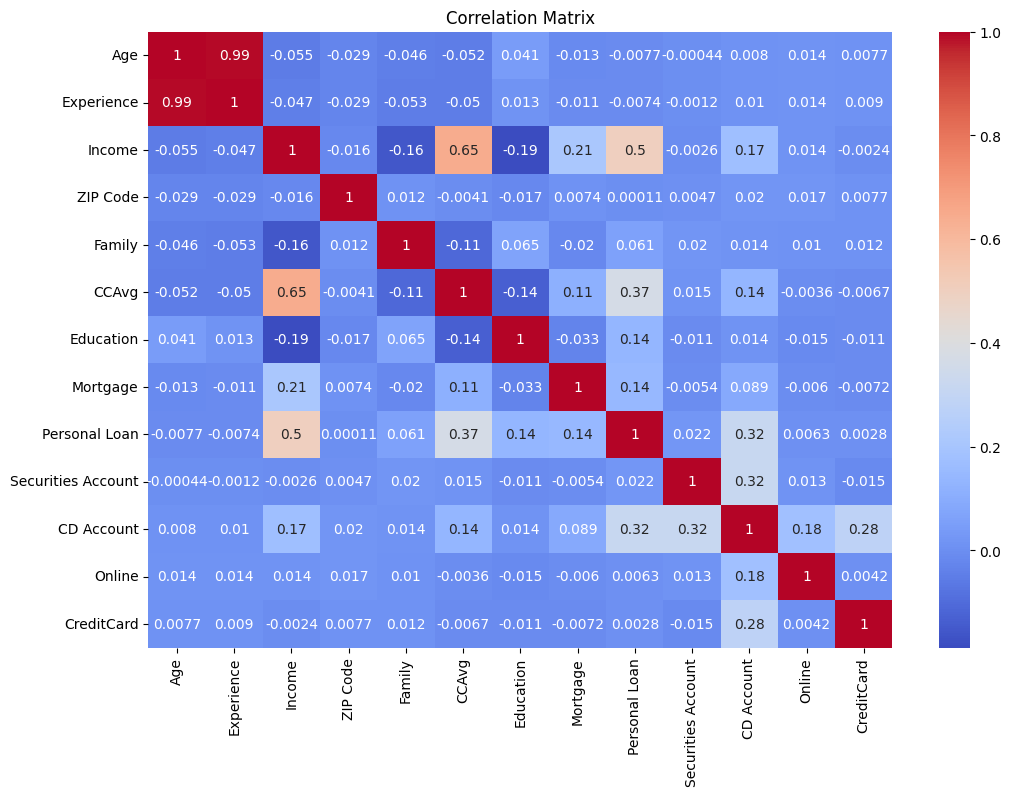

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

Age and Experience move together almost perfectly, and Income relates strongly to whether the loan is accepted. Pairs above roughly 0.85 would justify dropping one of them in a real project.

### Features and Target

In [11]:
X = df.drop("Personal Loan", axis=1)
y = df["Personal Loan"]

## Feature Scaling and Train-Test Split

Logistic regression and SVM both work with feature magnitudes and distances, so features are standardized to mean 0 and standard deviation 1 before splitting.

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)
print(len(X_train), "train rows,", len(X_test), "test rows")

4000 train rows, 1000 test rows


## Logistic Regression

Logistic regression is a classification algorithm. Instead of predicting a number directly, it converts a weighted sum of the features into a probability between 0 and 1 through the sigmoid function.

- Probability of 0.5 or above is classified as 1
- Anything below 0.5 is classified as 0

The coefficients of the model carry the meaning: a positive one pushes the customer toward accepting, a negative one pulls away from it.

### Training

In [13]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()
log_model.fit(X_train, y_train)

LogisticRegression()

### Predictions

In [14]:
y_pred = log_model.predict(X_test)          # final class, 0 or 1
y_prob = log_model.predict_proba(X_test)[:, 1]   # chance of class 1

print("Predicted classes:", y_pred[:10])
print("Predicted probabilities:", y_prob[:10].round(4))

Predicted classes: [0 0 0 0 0 0 0 0 0 0]
Predicted probabilities: [2.000e-04 2.629e-01 2.380e-02 1.000e-04 1.800e-03 1.900e-03 3.770e-02
 9.900e-03 9.800e-03 6.070e-02]


predict() returns the hard decision, predict_proba() returns the confidence behind it.

### Accuracy

In [15]:
from sklearn.metrics import accuracy_score

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

Accuracy: 0.955


### Confusion Matrix

The rows are actual classes and the columns are predicted ones. True positives are accepted loans caught correctly, true negatives are declined loans caught correctly, and the two off-diagonal cells are the mistakes.

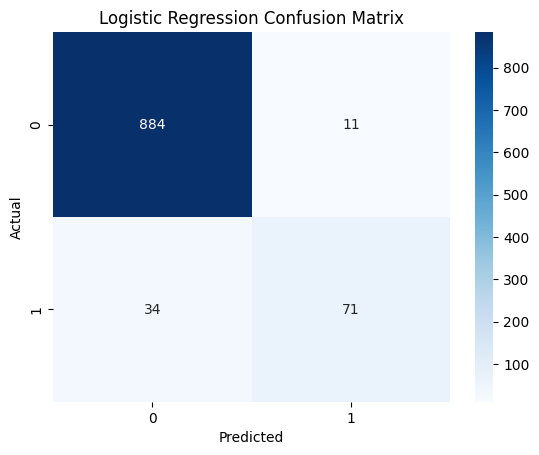

In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

### Classification Report

Precision asks how many of the customers flagged as likely accepters actually did, recall asks how many real accepters were found, F1 balances the two and support counts the samples per class.

In [17]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.99      0.98       895
           1       0.87      0.68      0.76       105

    accuracy                           0.95      1000
   macro avg       0.91      0.83      0.87      1000
weighted avg       0.95      0.95      0.95      1000



### ROC Curve and AUC

The curve traces the trade off between catching positives and raising false alarms. AUC summarizes that trade off in one number; closer to 1 is better.

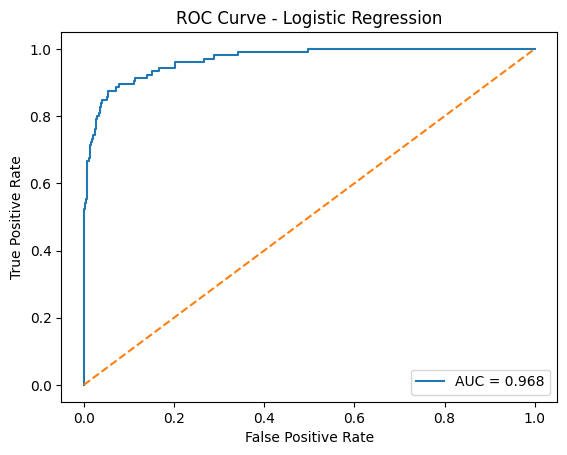

In [18]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

### Reading the Coefficients

In [19]:
coeff_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_model.coef_[0],
}).sort_values(by="Coefficient", ascending=False)

coeff_df

,Feature,Coefficient
2,Income,2.396703
6,Education,1.337324
9,CD Account,0.897669
4,Family,0.817753
1,Experience,0.405972
5,CCAvg,0.188878
7,Mortgage,0.054500
3,ZIP Code,-0.084800
8,Securities Account,-0.265740
0,Age,-0.280244


A larger positive coefficient means the feature lifts the probability of acceptance, a negative one lowers it, everything else held constant.

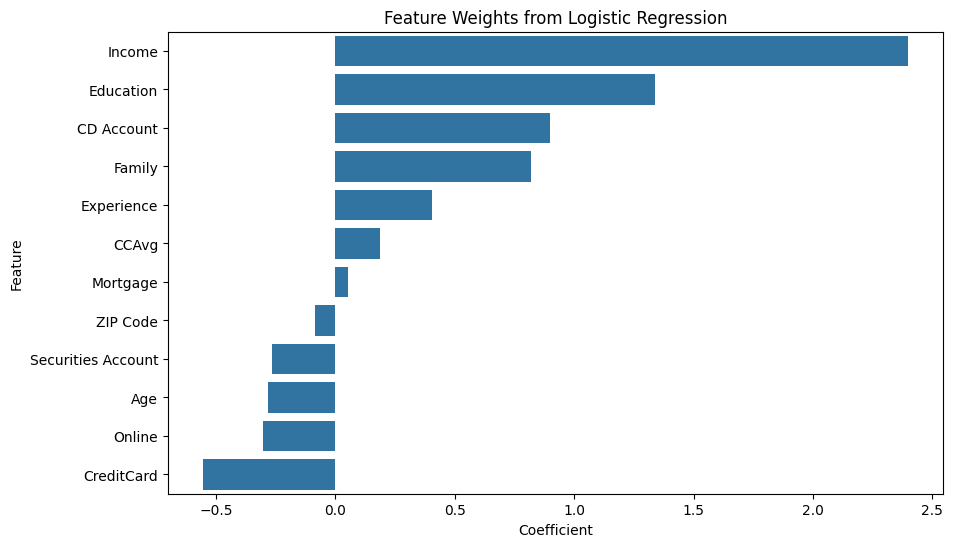

In [20]:
plt.figure(figsize=(10, 6))
sns.barplot(x="Coefficient", y="Feature", data=coeff_df)
plt.title("Feature Weights from Logistic Regression")
plt.show()

### Multicollinearity Check

Highly correlated inputs make coefficients unstable and confusing to read, which is confirmed with a value-labeled heatmap.

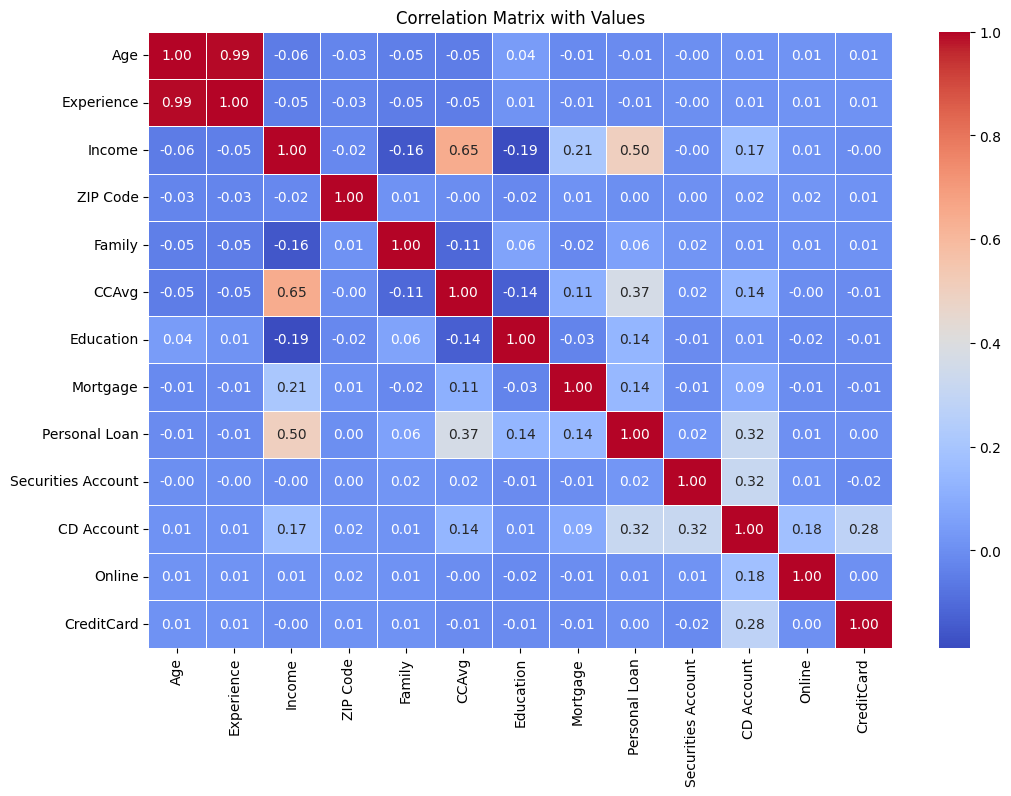

In [21]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix with Values")
plt.show()

## Regularization

Regularization adds a penalty on large coefficients to keep the model from overfitting.

- L1 (Lasso) can shrink weights all the way to zero, so it doubles as feature selection
- L2 (Ridge) just reduces their size while keeping every feature

In [22]:
log_model_l2 = LogisticRegression(penalty="l2")
log_model_l2.fit(X_train, y_train)

log_model_l1 = LogisticRegression(penalty="l1", solver="liblinear")
log_model_l1.fit(X_train, y_train)

print("L2 accuracy:", round(accuracy_score(y_test, log_model_l2.predict(X_test)), 4))
print("L1 accuracy:", round(accuracy_score(y_test, log_model_l1.predict(X_test)), 4))

L2 accuracy: 0.955
L1 accuracy: 0.955


Both variants arrive near the same accuracy, so no big gain comes from the penalty here, but the mechanics are worth knowing.

### Classification Report for the Multivariate Model

In [23]:
y_pred_multi = log_model.predict(X_test)
print("Multivariate Logistic Regression:\n")
print(classification_report(y_test, y_pred_multi))

Multivariate Logistic Regression:

              precision    recall  f1-score   support

           0       0.96      0.99      0.98       895
           1       0.87      0.68      0.76       105

    accuracy                           0.95      1000
   macro avg       0.91      0.83      0.87      1000
weighted avg       0.95      0.95      0.95      1000



## Predicting for a New Customer

A profile is described in the original feature order, scaled with the training statistics and passed to the model.

In [24]:
profile_columns = list(X.columns)

def predict_loan(profile_values):
    profile = pd.DataFrame(profile_values, columns=profile_columns)
    profile_scaled = scaler.transform(profile)
    vote = log_model.predict(profile_scaled)[0]
    confidence = log_model.predict_proba(profile_scaled)[0][1]
    if vote == 1:
        print(f"Customer is LIKELY to accept the loan (confidence: {confidence:.2f})")
    else:
        print(f"Customer is NOT likely to accept the loan (confidence: {1 - confidence:.2f})")
    return vote, confidence

# Representative middle-aged, high-income client
sample_profile = [[45, 20, 60, 400001, 2, 1.5, 2, 0, 1, 0, 1, 0]]
predict_loan(sample_profile)

Customer is NOT likely to accept the loan (confidence: 1.00)


(np.int64(0), np.float64(8.321721118418785e-09))

In [25]:
# A second profile: young, low-income customer
young_profile = [[25, 2, 20, 90001, 1, 0.3, 1, 40, 0, 0, 1, 0]]
predict_loan(young_profile)

Customer is NOT likely to accept the loan (confidence: 1.00)


(np.int64(0), np.float64(4.588895087114306e-05))

Logistic regression summary: simple, fast and easy to read, but it only draws straight boundaries and needs scaling plus care with outliers.

## Support Vector Machine

SVM searches for the boundary that separates the classes with the widest possible margin.

- Hyperplane: the separating surface, a line in two dimensions and a plane in higher ones
- Margin: the distance between the boundary and the nearest points
- Support vectors: the few points sitting right at the margin edge that define the boundary

Two modes exist. A hard margin forbids any mistake and only suits perfectly separable data. A soft margin tolerates some errors, with the C parameter controlling the balance: large C forgives less and risks overfitting, small C accepts more noise for better generalization.

When data is not linearly separable, kernels lift it into a higher dimension where a straight boundary works. Linear, polynomial and RBF kernels are the usual choices, with RBF the most common. Gamma controls how far each point's influence spreads: high gamma overfits, low gamma underfits.

### Training Linear and RBF Models

In [26]:
from sklearn.svm import SVC

svm_linear = SVC(kernel="linear", probability=True)
svm_linear.fit(X_train, y_train)

svm_rbf = SVC(kernel="rbf", probability=True)
svm_rbf.fit(X_train, y_train)

SVC(probability=True)

### Predictions

In [27]:
y_pred_svm = svm_rbf.predict(X_test)
y_prob_svm = svm_rbf.predict_proba(X_test)[:, 1]

### Accuracy

In [28]:
print("Linear SVM accuracy:", round(accuracy_score(y_test, svm_linear.predict(X_test)), 4))
print("RBF SVM accuracy   :", round(accuracy_score(y_test, y_pred_svm), 4))

Linear SVM accuracy: 0.953
RBF SVM accuracy   : 0.976


### Confusion Matrix

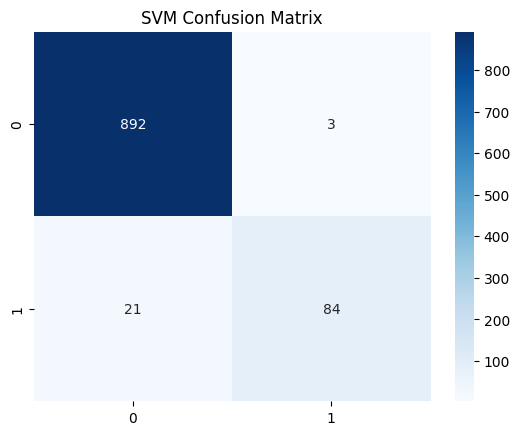

In [29]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues")
plt.title("SVM Confusion Matrix")
plt.show()

### Classification Report

In [30]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       895
           1       0.97      0.80      0.88       105

    accuracy                           0.98      1000
   macro avg       0.97      0.90      0.93      1000
weighted avg       0.98      0.98      0.97      1000



### ROC Curve

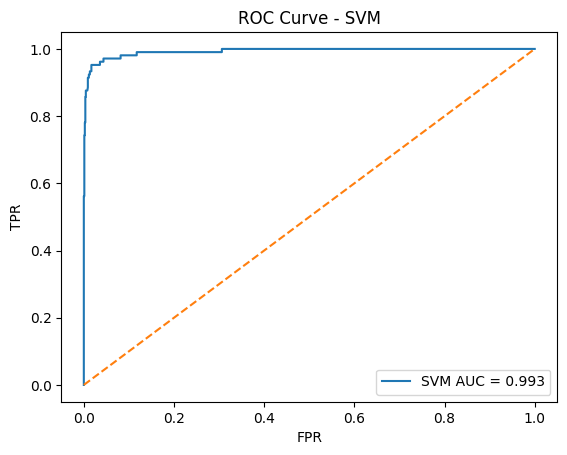

In [31]:
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
auc_svm = auc(fpr_svm, tpr_svm)

plt.plot(fpr_svm, tpr_svm, label=f"SVM AUC = {auc_svm:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC Curve - SVM")
plt.legend()
plt.show()

### Decision Boundary on a PCA Plot

Twelve inputs cannot be drawn directly, so PCA compresses everything to two dimensions purely for the picture.

In [32]:
import numpy as np

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

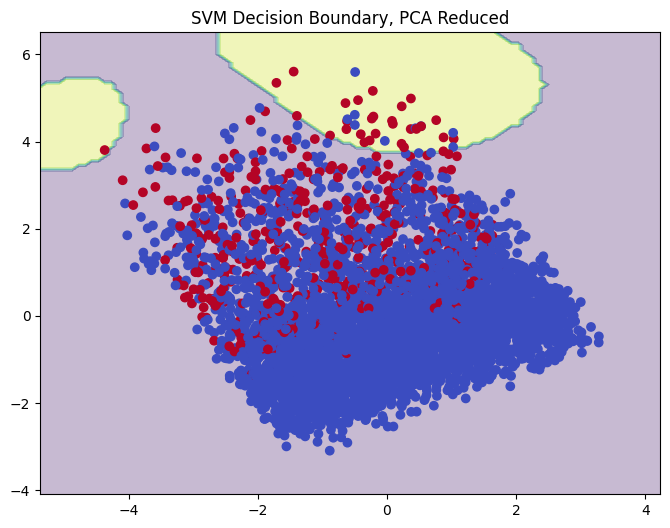

In [33]:
svm_vis = SVC(kernel="rbf")
svm_vis.fit(X_pca, y)

x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

Z = svm_vis.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm")
plt.title("SVM Decision Boundary, PCA Reduced")
plt.show()

### Separating Line with Margins and Support Vectors

A linear SVM is fitted on the same projection. The solid line is the hyperplane, the dashed lines are the margins, and the circled points are the support vectors that actually decide the boundary.

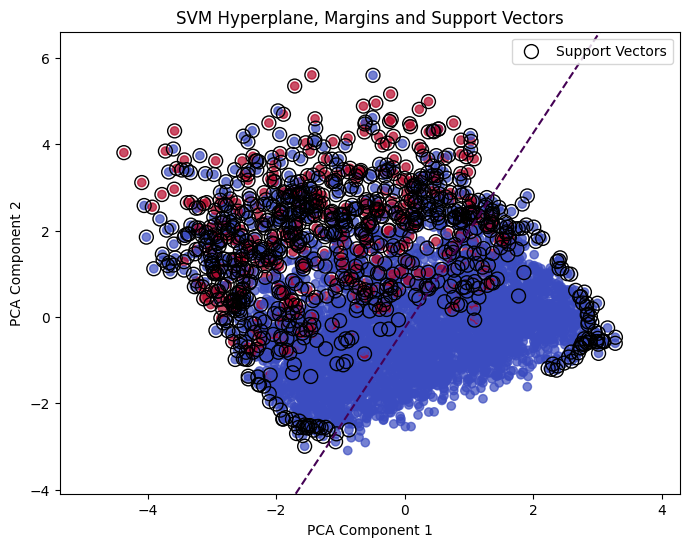

In [34]:
svm_flat = SVC(kernel="linear")
svm_flat.fit(X_pca, y)

xx, yy = np.meshgrid(
    np.linspace(X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1, 500),
    np.linspace(X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1, 500),
)

Z_margin = svm_flat.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contour(xx, yy, Z_margin, levels=[0], linewidths=2)
plt.contour(xx, yy, Z_margin, levels=[-1, 1], linestyles="dashed")
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", alpha=0.7)
plt.scatter(
    svm_flat.support_vectors_[:, 0],
    svm_flat.support_vectors_[:, 1],
    s=100, facecolors="none", edgecolors="k", label="Support Vectors",
)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("SVM Hyperplane, Margins and Support Vectors")
plt.legend()
plt.show()

SVM strengths: solid on high dimensional data, flexible boundaries through kernels, and it only needs the support vectors. Weaknesses: slow on big datasets, sensitive to C and gamma tuning, and harder to interpret than a tree.

## Decision Tree

A decision tree splits the data through a series of conditions, much like a flowchart. It serves both classification and regression.

Components:

- Root node: the starting question
- Decision nodes: intermediate conditions such as Income > 50
- Branches: the yes or no outcome of a condition
- Leaf nodes: the final answer

Splitting is judged by how pure each resulting group is. Common measures are Gini impurity and Entropy (Information Gain) - the split with the cleanest separation wins. Both hit 0 at a completely uniform node and rise as classes mix.

### Training

In [35]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

### Predictions

In [36]:
y_pred_dt = dt_model.predict(X_test)

### Accuracy

In [37]:
print("Decision Tree Accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))

Decision Tree Accuracy: 0.986


### Confusion Matrix

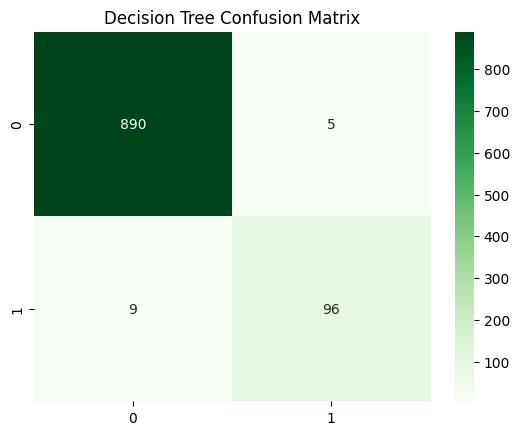

In [38]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.show()

### Classification Report

In [39]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       895
           1       0.95      0.91      0.93       105

    accuracy                           0.99      1000
   macro avg       0.97      0.95      0.96      1000
weighted avg       0.99      0.99      0.99      1000



### Drawing the Tree

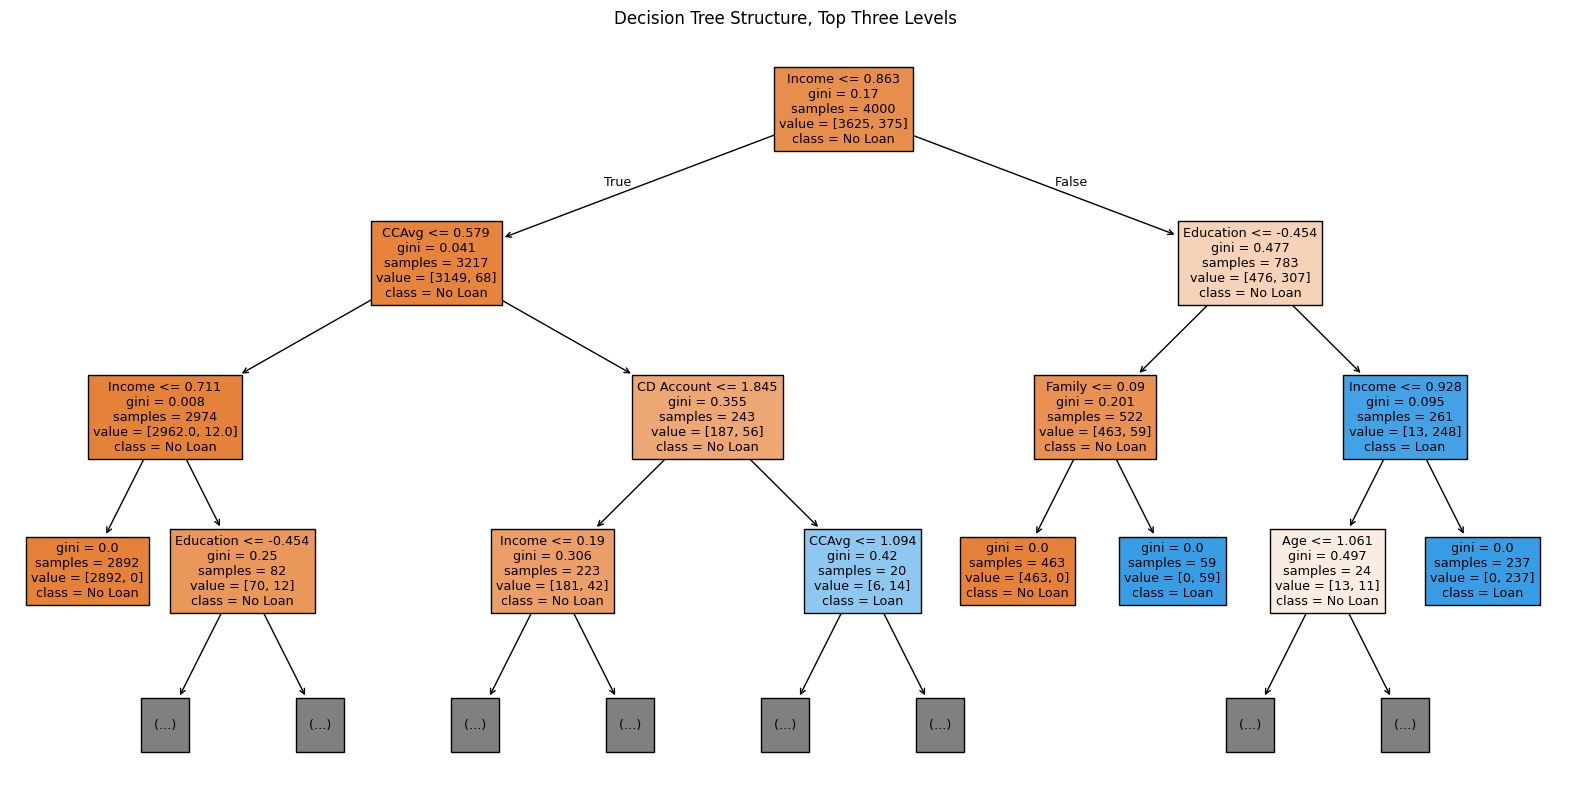

In [40]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["No Loan", "Loan"],
    filled=True,
    max_depth=3,
)
plt.title("Decision Tree Structure, Top Three Levels")
plt.show()

The full drawn tree can be deep, so the plot is trimmed to three levels for readability.

### Graphviz Export

The same tree can be exported with graphviz for a cleaner rendering when the package is available.

In [41]:
from sklearn.tree import export_graphviz
import graphviz

try:
    dot_data = export_graphviz(
        dt_model,
        out_file=None,
        feature_names=X.columns,
        class_names=["No Loan", "Loan"],
        filled=True,
        rounded=True,
        special_characters=True,
    )
    graph = graphviz.Source(dot_data)
    graph
except (ImportError, Exception) as err:
    print("Graphviz export skipped:", type(err).__name__)

## Overfitting in Decision Trees

An untrimmed tree happily memorizes the training rows: near perfect training accuracy but weaker test accuracy. Limiting the depth and the minimum split size keeps the tree honest.

In [42]:
dt_limited = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    random_state=42,
)
dt_limited.fit(X_train, y_train)

print("Full tree  test accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print("Limited tree test accuracy:", round(accuracy_score(y_test, dt_limited.predict(X_test)), 4))

Full tree  test accuracy: 0.986
Limited tree test accuracy: 0.984


### Feature Importance

In [43]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt_model.feature_importances_,
}).sort_values(by="Importance", ascending=False)

importance

,Feature,Importance
6,Education,0.379124
2,Income,0.302545
4,Family,0.185207
5,CCAvg,0.054980
0,Age,0.022519
1,Experience,0.015559
9,CD Account,0.014139
10,Online,0.010254
3,ZIP Code,0.008785
7,Mortgage,0.005418


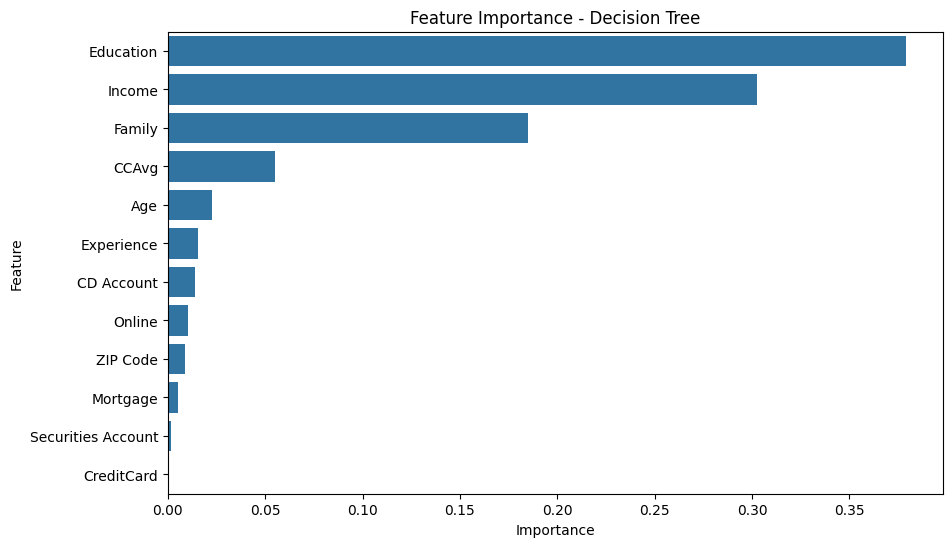

In [44]:
plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=importance)
plt.title("Feature Importance - Decision Tree")
plt.show()

Income, education and credit card spending dominate the splits, matching what logistic regression reported through its coefficients.

### Decision Boundary on a PCA Plot

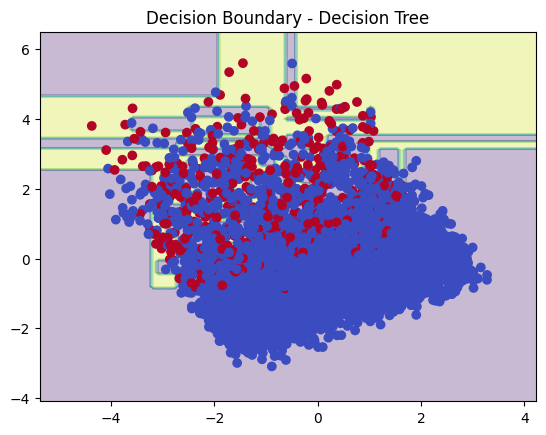

In [45]:
dt_vis = DecisionTreeClassifier(random_state=42)
dt_vis.fit(X_pca, y)

xx, yy = np.meshgrid(
    np.arange(X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1, 0.1),
    np.arange(X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1, 0.1),
)

Z_dt = dt_vis.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contourf(xx, yy, Z_dt, alpha=0.3)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm")
plt.title("Decision Boundary - Decision Tree")
plt.show()

The tree carves blocky regions instead of the smooth curves of the RBF kernel, which is the visual signature of rule based splits.

## Comparing the Four Models

| Aspect | Logistic Regression | Multivariate Logistic | SVM | Decision Tree |
|--------|----------------------|------------------------|-----|----------------|
| Type | Linear model | Linear model | Linear plus kernels | Non-linear |
| Output | Probability | Probability | Class label | Class label |
| Boundary | Linear | Linear | Linear or non-linear | Non-linear, hierarchical |
| Interpretability | High | High | Low | Very high |
| Scaling needed | Yes | Yes | Yes | No |
| Overfitting risk | Low | Low | Medium | High |
| Hyperparameters | Few | Few | Many (C, gamma, kernel) | Few (depth, split) |
| Best for | Simple problems | Real-world baseline | Complex boundaries | Rule-based decisions |

When to reach for each one:

- Logistic Regression: mostly linear data with an interpretable baseline
- Multivariate Logistic: the same model when several features act together, the everyday real-world starter
- SVM: complex or high-dimensional data where kernels earn their keep
- Decision Tree: when the result has to be explained as readable rules